In [1]:
# Step 1: Install and import required libraries

!pip install ultralytics

import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files
from ultralytics import YOLO

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.7/46.7 kB 1.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 35.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.1/58.1 kB 3.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 91.1/91.1 kB 7.0 MB/s eta 0:00:00
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.


In [2]:
# Step 2: Load the pre-trained YOLOv8 model

model = YOLO("yolov8n.pt")

print("YOLOv8 model loaded successfully.")

YOLOv8 model loaded successfully.


Saving cute-animals-group-white-background_23-2150038555.avif to cute-animals-group-white-background_23-2150038555.avif


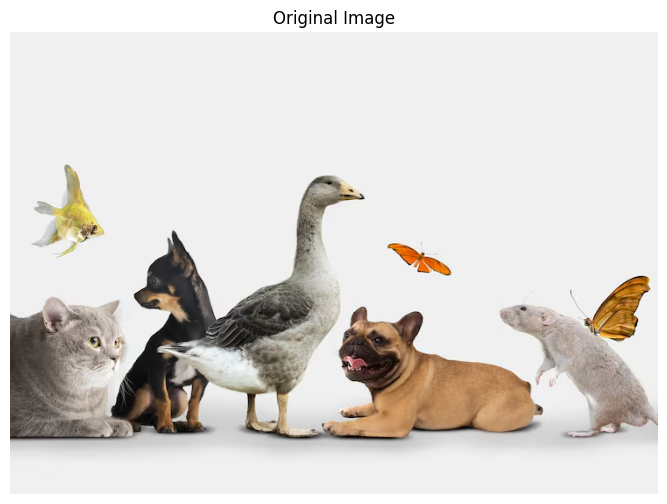

In [3]:
# Step 3: Upload and load an image

uploaded = files.upload()

image_path = list(uploaded.keys())[0]

image = cv2.imread(image_path)

if image is None:
    print("Error: Image not found.")
else:
    image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    plt.figure(figsize=(10, 6))
    plt.imshow(image_rgb)
    plt.title("Original Image")
    plt.axis("off")
    plt.show()

In [4]:
# Step 4: Preprocess the image

image_resized = cv2.resize(image, (640, 640))

image_rgb = cv2.cvtColor(image_resized, cv2.COLOR_BGR2RGB)

print("Original Image Size:", image.shape[:2])
print("Resized Image Size:", image_resized.shape[:2])

Original Image Size: (528, 740)
Resized Image Size: (640, 640)


In [5]:
# Step 5: Apply YOLO object detection

results = model(image_resized)

print("Object detection completed.")


0: 640x640 4 birds, 1 cat, 3 dogs, 409.3ms
Speed: 18.0ms preprocess, 409.3ms inference, 43.6ms postprocess per image at shape (1, 3, 640, 640)
Object detection completed.


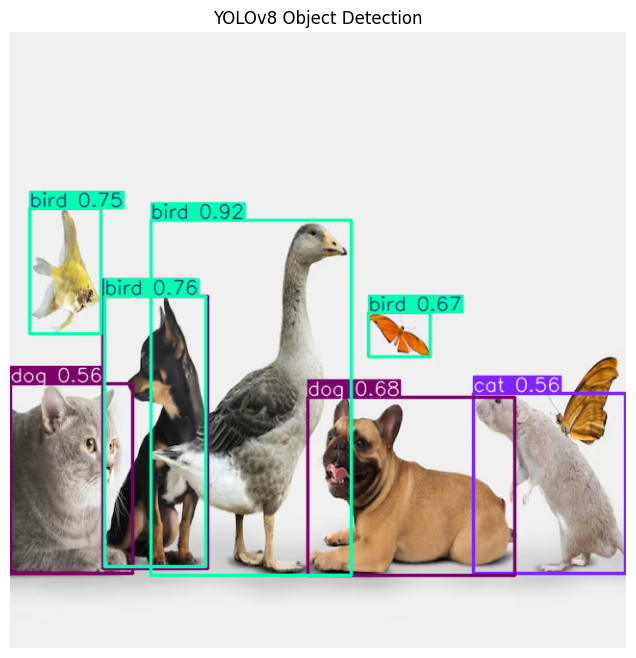

In [6]:
# Step 6: Display detected objects with bounding boxes and confidence scores

result_image = results[0].plot()

result_rgb = cv2.cvtColor(result_image, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(12, 8))
plt.imshow(result_rgb)
plt.title("YOLOv8 Object Detection")
plt.axis("off")
plt.show()

In [7]:
# Step 7: Analyze detection results

boxes = results[0].boxes

if boxes is not None and len(boxes) > 0:
    print("Detected Objects:")

    for box in boxes:
        class_id = int(box.cls[0])
        confidence = float(box.conf[0])
        class_name = model.names[class_id]

        print(
            "Object:",
            class_name,
            "| Confidence:",
            round(confidence * 100, 2),
            "%"
        )

    print("\nTotal Objects Detected:", len(boxes))
else:
    print("No objects detected.")

Detected Objects:
Object: bird | Confidence: 92.32 %
Object: bird | Confidence: 75.88 %
Object: bird | Confidence: 74.66 %
Object: dog | Confidence: 67.53 %
Object: bird | Confidence: 66.86 %
Object: dog | Confidence: 55.95 %
Object: cat | Confidence: 55.73 %
Object: dog | Confidence: 25.39 %

Total Objects Detected: 8


In [8]:
# Step 8: Measure detection speed

import time

start_time = time.time()

results_speed = model(image_resized)

end_time = time.time()

inference_time = end_time - start_time

print("Inference Time:", round(inference_time, 4), "seconds")

if inference_time > 0:
    fps = 1 / inference_time
    print("Approximate FPS:", round(fps, 2))


0: 640x640 4 birds, 1 cat, 3 dogs, 143.3ms
Speed: 6.1ms preprocess, 143.3ms inference, 1.2ms postprocess per image at shape (1, 3, 640, 640)
Inference Time: 0.1574 seconds
Approximate FPS: 6.35


In [9]:
# Step 9: Analyze suitability for real-world applications

print("YOLOv8 Applications:")
print("1. Autonomous Driving - Detection of vehicles, pedestrians and traffic objects.")
print("2. Surveillance - Detection and monitoring of people and objects.")
print("3. Retail Analytics - Detection of customers and products.")
print("4. Industrial Inspection - Detection of objects and manufacturing defects.")

print("\nAdvantages:")
print("- Fast object detection.")
print("- Detects multiple objects in a single image.")
print("- Provides bounding boxes and confidence scores.")
print("- Suitable for real-time applications.")

print("\nLimitations:")
print("- Detection accuracy depends on image quality.")
print("- Small or heavily occluded objects may be missed.")
print("- Pre-trained models may not recognize specialized objects.")

YOLOv8 Applications:
1. Autonomous Driving - Detection of vehicles, pedestrians and traffic objects.
2. Surveillance - Detection and monitoring of people and objects.
3. Retail Analytics - Detection of customers and products.
4. Industrial Inspection - Detection of objects and manufacturing defects.

Advantages:
- Fast object detection.
- Detects multiple objects in a single image.
- Provides bounding boxes and confidence scores.
- Suitable for real-time applications.

Limitations:
- Detection accuracy depends on image quality.
- Small or heavily occluded objects may be missed.
- Pre-trained models may not recognize specialized objects.


In [10]:
# Step 10: Summarize observations

print("Observations:")
print("1. A pre-trained YOLOv8 model was used for object detection.")
print("2. The input image was resized before inference.")
print("3. YOLO detected objects and displayed their bounding boxes.")
print("4. Class labels and confidence scores were obtained for detected objects.")
print("5. Detection speed was measured using inference time.")
print("6. Deep learning-based object detection is useful for surveillance,")
print("   autonomous driving, retail analytics and industrial inspection.")
print("7. YOLO provides fast detection but may miss very small or occluded objects.")

Observations:
1. A pre-trained YOLOv8 model was used for object detection.
2. The input image was resized before inference.
3. YOLO detected objects and displayed their bounding boxes.
4. Class labels and confidence scores were obtained for detected objects.
5. Detection speed was measured using inference time.
6. Deep learning-based object detection is useful for surveillance,
   autonomous driving, retail analytics and industrial inspection.
7. YOLO provides fast detection but may miss very small or occluded objects.
